---
title: "Induction and Maxwell's Equations — Level 2"
short_title: "07 Induction & Maxwell"
numbering:
  heading_2: true
  equation: true
---

# Induction and Maxwell's Equations

:::{seealso} Math for this topic
- [E-M1: Vector calculus for fields](../math/01-vector-calculus-fields.ipynb)
- [M3: Multivariable calculus](../../level2-book/math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 28 and 30 | Faraday's law on a loop, Lenz's law |
| **2** | **Griffiths, ch. 7–8** | **Differential form of Maxwell's equations, displacement current, conservation laws** |
| 3 | Jackson, ch. 5–6 | Gauge transformations, Green's functions for the wave equation, conservation laws |

The new skill at this level: letting fields change in time, which couples E and B into one system and gives the field its own energy flow

Math for this topic: E-M1 (vector calculus) and mechanics M3 (partial derivatives).
:::

Workbook example ladder: moving rod in a B field → displacement current in a capacitor → Poynting's theorem and field momentum. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Motional EMF

The **electromotive force** around a circuit is the work per unit charge done by whatever pushes the charges around, $\mathcal{E} = \oint\vec{f}\cdot d\vec{l}$. In a conductor obeying Ohm's law ($\vec{J} = \sigma\vec{E}$), an EMF drives a current $I = \mathcal{E}/R$.

A conducting rod of length $L$ slides at speed $v$ along two rails in a uniform field $B$ perpendicular to the circuit. The charges in the rod move with it, so they feel $q\vec{v}\times\vec{B}$ along the rod, and

$$
\mathcal{E} = BLv = -\frac{d\Phi}{dt} ,
$$

where $\Phi = BLx$ is the flux through the circuit. The magnetic force does no work on the charges; the work is done by whatever pushes the rod.

::::{prf:example} Magnetic braking
:label: ex-magnetic-braking

The rod has mass $m$, the circuit has resistance $R$, and the rod is given an initial speed $v_0$ and released. Find $v(t)$ and the total energy dissipated.

:::{dropdown} Solution
The current $I = BLv/R$ in the rod feels a force $ILB$ opposing the motion (Lenz's law). Newton's law:

$$
m\dot v = -\frac{B^2L^2}{R}v \quad\Longrightarrow\quad v = v_0e^{-t/\tau}, \qquad \tau = \frac{mR}{B^2L^2} .
$$

The power dissipated is $I^2R = B^2L^2v^2/R$, and its integral over all time is $\tfrac12mv_0^2$: all of the kinetic energy becomes heat in the resistor. This is the linear drag of the Newton's-laws notes, with an electromagnetic origin.
:::
::::

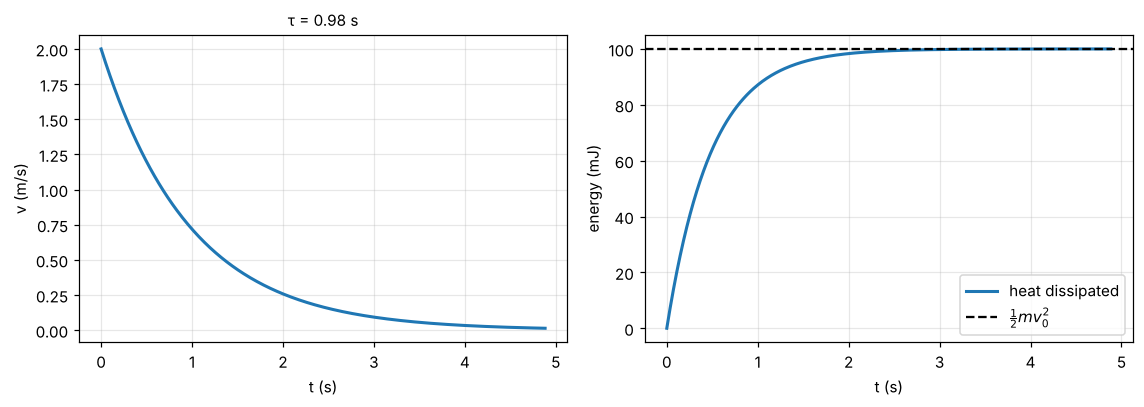

In [2]:
#| label: fig-magnetic-braking
#| caption: A rod coasting on rails in a magnetic field. Its speed decays exponentially (left); the heat dissipated in the resistor rises to exactly the initial kinetic energy (right).
m_, R_, B_, L_, v0 = 0.05, 0.5, 0.8, 0.2, 2.0
tau = m_ * R_ / (B_ * L_)**2
t = np.linspace(0, 5 * tau, 400)
v = v0 * np.exp(-t / tau)
P = (B_ * L_ * v)**2 / R_
heat = np.concatenate([[0], np.cumsum(0.5 * (P[1:] + P[:-1]) * np.diff(t))])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].plot(t, v, lw=2); axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("v (m/s)"); axes[0].set_title(f"τ = {tau:.2f} s", fontsize=10)
axes[1].plot(t, heat * 1e3, lw=2, label="heat dissipated")
axes[1].axhline(0.5 * m_ * v0**2 * 1e3, color="k", ls="--", label=r"$\frac{1}{2} m v_0^2$")
axes[1].set_xlabel("t (s)"); axes[1].set_ylabel("energy (mJ)"); axes[1].legend()
plt.tight_layout(); plt.show()

## Faraday's Law

Faraday found that a changing magnetic field induces an EMF in a **stationary** loop too, with the same flux rule. With no moving conductor to supply a $\vec{v}\times\vec{B}$ force, the cause must be an electric field:

$$
\oint\vec{E}\cdot d\vec{l} = -\frac{d}{dt}\int\vec{B}\cdot d\vec{a}
\qquad\Longleftrightarrow\qquad
\nabla\times\vec{E} = -\frac{\partial\vec{B}}{\partial t} .
$$ (eq-faraday)

This **induced electric field** has a curl, so it is not conservative and has no scalar potential; its field lines can close on themselves. The minus sign is **Lenz's law**: the induced current flows so as to oppose the change in flux.

::::{prf:example} The field around a changing solenoid
:label: ex-solenoid-induced-E

A long solenoid of radius $R$ has a uniform interior field $B(t)$. Find the induced $\vec{E}$ inside and outside.

:::{dropdown} Solution
By symmetry $\vec{E} = E(s)\hat{\phi}$. Apply {eq}`eq-faraday` to a circle of radius $s$:

$$
2\pi sE = -\frac{d}{dt}\begin{cases}\pi s^2B & s < R\\ \pi R^2B & s > R\end{cases}
\quad\Longrightarrow\quad
E = \begin{cases}-\dfrac s2\dfrac{dB}{dt} & s < R\\[6pt] -\dfrac{R^2}{2s}\dfrac{dB}{dt} & s > R\end{cases}
$$

Outside, $\vec{B} = \vec{0}$ but $\vec{E}\neq\vec{0}$: a loop around the solenoid feels an EMF even though no magnetic field touches it. (Notice that $\vec{E} = -\partial\vec{A}/\partial t$ with the solenoid's $\vec{A}$ from the magnetostatics notes.)
:::
::::

## Inductance and Magnetic Energy

The flux through loop 2 due to current $I_1$ in loop 1 is proportional to $I_1$: $\Phi_2 = M_{21}I_1$. Writing the flux as $\oint\vec{A}_1\cdot d\vec{l}_2$ and using {eq}`eq-vector-potential` from the magnetostatics notes gives the **Neumann formula**,

$$
M_{21} = \frac{\mu_0}{4\pi}\oint\oint\frac{d\vec{l}_1\cdot d\vec{l}_2}{|\vec{r}_1 - \vec{r}_2|} = M_{12} ,
$$ (eq-neumann)

which is purely geometric and symmetric. A loop also links its own flux, $\Phi = LI$, defining its **self-inductance** $L$; for a long solenoid, $L = \mu_0n^2A\ell$. Changing currents induce back-EMFs $-L\,dI/dt$, so building up a current takes work, stored as

$$
W = \tfrac12LI^2 = \frac{1}{2\mu_0}\int B^2\,d\tau ,
$$

the magnetic counterpart of the electric field energy.

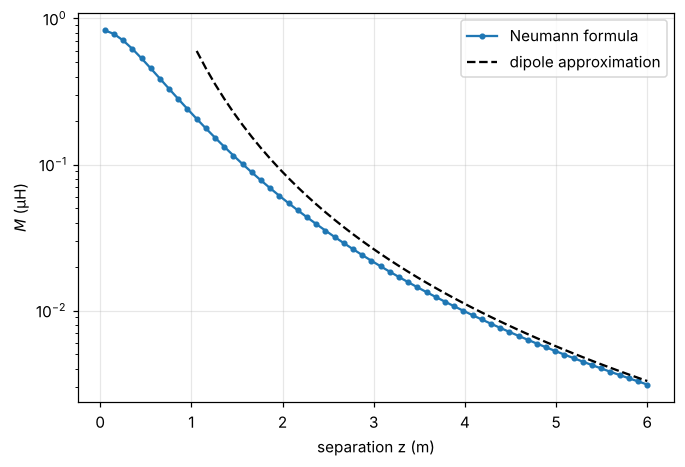

In [3]:
#| label: fig-mutual-inductance
#| caption: Mutual inductance of two coaxial loops (radii a = 1 and b = 0.6, in meters) versus separation, from the Neumann double integral. Far apart it approaches the dipole approximation μ₀πa²b²/(2z³).
def neumann(a, b, z, n=400):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    p1 = np.c_[a * np.cos(t), a * np.sin(t), np.zeros(n)]
    d1 = np.c_[-np.sin(t), np.cos(t), np.zeros(n)] * a * (2 * np.pi / n)
    p2 = np.c_[b * np.cos(t), b * np.sin(t), np.full(n, z)]
    d2 = np.c_[-np.sin(t), np.cos(t), np.zeros(n)] * b * (2 * np.pi / n)
    dist = np.linalg.norm(p1[:, None, :] - p2[None, :, :], axis=-1)
    return mu0 / (4 * np.pi) * np.sum((d1 @ d2.T) / dist)
a_, b_ = 1.0, 0.6
zs = np.linspace(0.05, 6, 60)
M = [neumann(a_, b_, z_) for z_ in zs]
fig, ax = plt.subplots()
ax.semilogy(zs, np.array(M) * 1e6, "o-", ms=3, label="Neumann formula")
ax.semilogy(zs[zs > 1], mu0 * np.pi * a_**2 * b_**2 / (2 * zs[zs > 1]**3) * 1e6, "k--", label="dipole approximation")
ax.set_xlabel("separation z (m)"); ax.set_ylabel(r"$M$ (μH)"); ax.legend(); plt.show()

### Exercises

1. A square loop of side $\ell$ and resistance $R$ is pulled at constant speed $v$ out of a region of uniform field $B$. What force is needed, and where does the work go?
2. The field inside a solenoid of radius $5$ cm rises at $20$ T/s. Find the induced field at $s = 3$ cm and at $s = 10$ cm.
3. Show that the energy stored in a long solenoid, $\tfrac12LI^2$, equals $\frac{1}{2\mu_0}\int B^2\,d\tau$.

:::{dropdown} Hints
1. Only one side cuts field lines; the EMF is $B\ell v$.
2. Use the solenoid example.
3. $B = \mu_0nI$ uniform inside a volume $A\ell$; $L = \mu_0n^2A\ell$.
:::

:::{dropdown} Answers
1. $F = B^2\ell^2v/R$; the power $Fv$ appears as Joule heat $I^2R$.
2. $E = 0.3$ V/m at $3$ cm and $0.25$ V/m at $10$ cm, circulating opposite to the current that would increase $B$.
3. $\frac{1}{2\mu_0}(\mu_0nI)^2A\ell = \tfrac12\mu_0n^2A\ell I^2 = \tfrac12LI^2$.
:::

## The Displacement Current

Collect the equations so far: $\nabla\cdot\vec{E} = \rho/\epsilon_0$, $\nabla\cdot\vec{B} = 0$, Faraday's law, and Ampère's law $\nabla\times\vec{B} = \mu_0\vec{J}$. The last one has a problem. The divergence of a curl is zero, so it demands $\nabla\cdot\vec{J} = 0$, which fails whenever charge piles up (charging a capacitor, for instance).

Maxwell's fix: by the continuity equation and Gauss's law, $\nabla\cdot\vec{J} = -\partial\rho/\partial t = -\nabla\cdot(\epsilon_0\,\partial\vec{E}/\partial t)$. So adding $\epsilon_0\,\partial\vec{E}/\partial t$ to the current makes the divergence consistent:

$$
\nabla\times\vec{B} = \mu_0\vec{J} + \mu_0\epsilon_0\frac{\partial\vec{E}}{\partial t} .
$$

The new term, the **displacement current**, says a changing electric field produces a magnetic field, just as a changing magnetic field produces an electric one. Between the plates of a charging capacitor (circular plates of radius $R$, current $I$ in the wires), it gives

$$
B(s) = \frac{\mu_0Is}{2\pi R^2}\quad(s < R) ,
$$

exactly the field inside a wire carrying the same current. Ampère's law now gives the same answer whether the loop's surface cuts the wire or passes between the plates.

## Maxwell's Equations

$$
\begin{aligned}
\nabla\cdot\vec{E} &= \frac{\rho}{\epsilon_0}, & \nabla\times\vec{E} &= -\frac{\partial\vec{B}}{\partial t}, \\
\nabla\cdot\vec{B} &= 0, & \nabla\times\vec{B} &= \mu_0\vec{J} + \mu_0\epsilon_0\frac{\partial\vec{E}}{\partial t} .
\end{aligned}
$$ (eq-maxwell)

Together with the Lorentz force law, these contain all of classical electrodynamics. In matter, written with free charges and currents, they become $\nabla\cdot\vec{D} = \rho_f$ and $\nabla\times\vec{H} = \vec{J}_f + \partial\vec{D}/\partial t$, with the other two unchanged.

In empty space, the two curl equations feed each other: a changing $\vec{E}$ makes $\vec{B}$, a changing $\vec{B}$ makes $\vec{E}$. The next topic shows that this produces waves traveling at $1/\sqrt{\mu_0\epsilon_0}$.

In [4]:
print("1/sqrt(mu0 eps0) =", f"{1 / np.sqrt(mu0 * eps0):.4e}", "m/s")

1/sqrt(mu0 eps0) = 2.9980e+08 m/s


## Conservation of Energy: Poynting's Theorem

The rate at which the fields do work on charges in a volume $V$ is $\int\vec{E}\cdot\vec{J}\,d\tau$ (magnetic forces do no work). Eliminating $\vec{J}$ with the Ampère–Maxwell law and using the product rule for $\nabla\cdot(\vec{E}\times\vec{B})$ (E-M1) gives

$$
\frac{dW_{\text{mech}}}{dt} = -\frac{d}{dt}\int_V\left(\frac{\epsilon_0}{2}E^2 + \frac{1}{2\mu_0}B^2\right)d\tau - \oint_{\partial V}\vec{S}\cdot d\vec{a}, \qquad
\vec{S} = \frac{1}{\mu_0}\vec{E}\times\vec{B} .
$$ (eq-poynting)

Work done on charges comes from a decrease in field energy inside $V$ or from energy flowing **in** through the boundary. The **Poynting vector** $\vec{S}$ is that energy flux (W/m²).

The fields also carry **momentum**, with density $\vec{g} = \epsilon_0\vec{E}\times\vec{B} = \vec{S}/c^2$, and angular momentum. That is what saves momentum conservation in the cases where the third law fails for magnetic forces (the Newton's-laws notes).

In [5]:
# Poynting check for a resistive wire: E along the wire, B circling it. The inward flux through the surface equals I^2 R.
I, R_w, L_w, sig = sp.symbols("I a L sigma", positive=True)
E = I / (sig * sp.pi * R_w**2)                   # E = J / sigma
B = sp.Symbol("mu_0", positive=True) * I / (2 * sp.pi * R_w)
S = E * B / sp.Symbol("mu_0", positive=True)     # magnitude, pointing radially inward
power_in = S * 2 * sp.pi * R_w * L_w
resistance = L_w / (sig * sp.pi * R_w**2)
display(Math(r"\text{inward Poynting flux} = " + sp.latex(sp.simplify(power_in)) + r",\qquad I^2 R = " + sp.latex(sp.simplify(I**2 * resistance))))

<IPython.core.display.Math object>

### Exercises

1. Verify that the displacement current between the plates of a charging parallel-plate capacitor equals the conduction current $I$ in the wires.
2. Show that {eq}`eq-maxwell` implies the continuity equation $\nabla\cdot\vec{J} = -\partial\rho/\partial t$.
3. In the wire example above, which way does $\vec{S}$ point, and what does that say about how energy reaches a resistor?

:::{dropdown} Hints
1. $E = \sigma/\epsilon_0 = Q/(\epsilon_0A)$ between the plates.
2. Take the divergence of the Ampère–Maxwell equation.
3. $\vec{E}$ is along the current, $\vec{B}$ circles it; use the right-hand rule.
:::

:::{dropdown} Answers
1. $\epsilon_0\dfrac{dE}{dt}A = \dfrac{dQ}{dt} = I$.
2. $0 = \mu_0\nabla\cdot\vec{J} + \mu_0\epsilon_0\,\partial_t(\nabla\cdot\vec{E}) = \mu_0\left(\nabla\cdot\vec{J} + \partial_t\rho\right)$.
3. Radially inward. The energy dissipated in a resistor flows in through the surrounding space, guided by the wires, not along the inside of the wire.
:::

## Summary

- A conductor moving through $\vec{B}$ gets a motional EMF; the flux rule $\mathcal{E} = -d\Phi/dt$ covers it and Faraday induction alike.
- $\nabla\times\vec{E} = -\partial\vec{B}/\partial t$: changing magnetic fields create non-conservative electric fields, opposing the change (Lenz).
- Mutual inductance is geometric and symmetric (Neumann); magnetic energy is $\tfrac12LI^2 = \frac{1}{2\mu_0}\int B^2$.
- The displacement current $\mu_0\epsilon_0\partial\vec{E}/\partial t$ makes Ampère's law consistent with charge conservation and completes Maxwell's equations.
- Energy flows with the Poynting vector $\vec{E}\times\vec{B}/\mu_0$; fields carry energy and momentum.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.